图像已保存至: ./convex_landscape.pdf


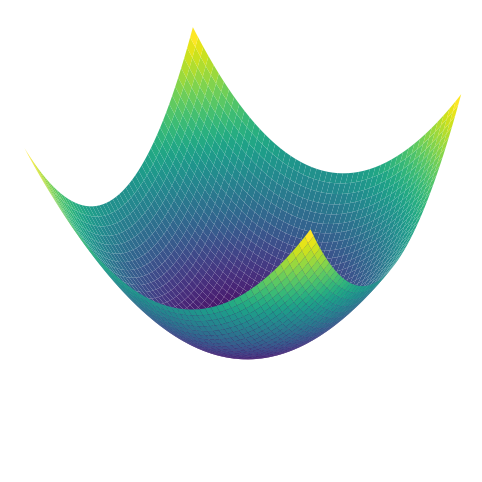

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D

def plot_bowl_surface(
    range_xy=(-2, 2),
    resolution=600,
    cmap='viridis',
    output_file='cover_bowl_tight.pdf',
    save=True,
    show=True
):
    x = np.linspace(range_xy[0], range_xy[1], resolution)
    y = np.linspace(range_xy[0], range_xy[1], resolution)
    x, y = np.meshgrid(x, y)
    z = x**2 + y**2

    fig = plt.figure(figsize=(10, 6), facecolor='white')
    ax = fig.add_subplot(111, projection='3d')

    # 绘制曲面
    surf = ax.plot_surface(
        x, y, z,
        cmap=cmap,
        edgecolor='none',
        antialiased=True,
        shade=True,
    )

    # 隐藏所有坐标轴元素
    ax.set_axis_off()
    # 确保背板也完全隐藏
    ax.xaxis.pane.set_visible(False)
    ax.yaxis.pane.set_visible(False)
    ax.zaxis.pane.set_visible(False)

    # 缩放视图，让碗占据更多画面
    ax.set_box_aspect(None, zoom=1.2)

    # 不再使用 set_position 强行拉伸，交给 tight bbox 自动裁剪
    # ax.set_position([0, 0, 1, 1])   # 去掉这行

    if save:
        plt.savefig(
            output_file,
            format='pdf',
            bbox_inches='tight',      # 自动裁剪到曲面边界
            pad_inches=0,             # 零边距
            transparent=True
        )
        print(f"图像已保存至: {output_file}")

    plt.show()
    plt.close(fig)

# 运行生成
plot_bowl_surface(
    resolution=600,
    cmap='viridis',
    output_file='./convex_landscape.pdf'
)

图像已保存至: ./nonconvex_landscape.pdf


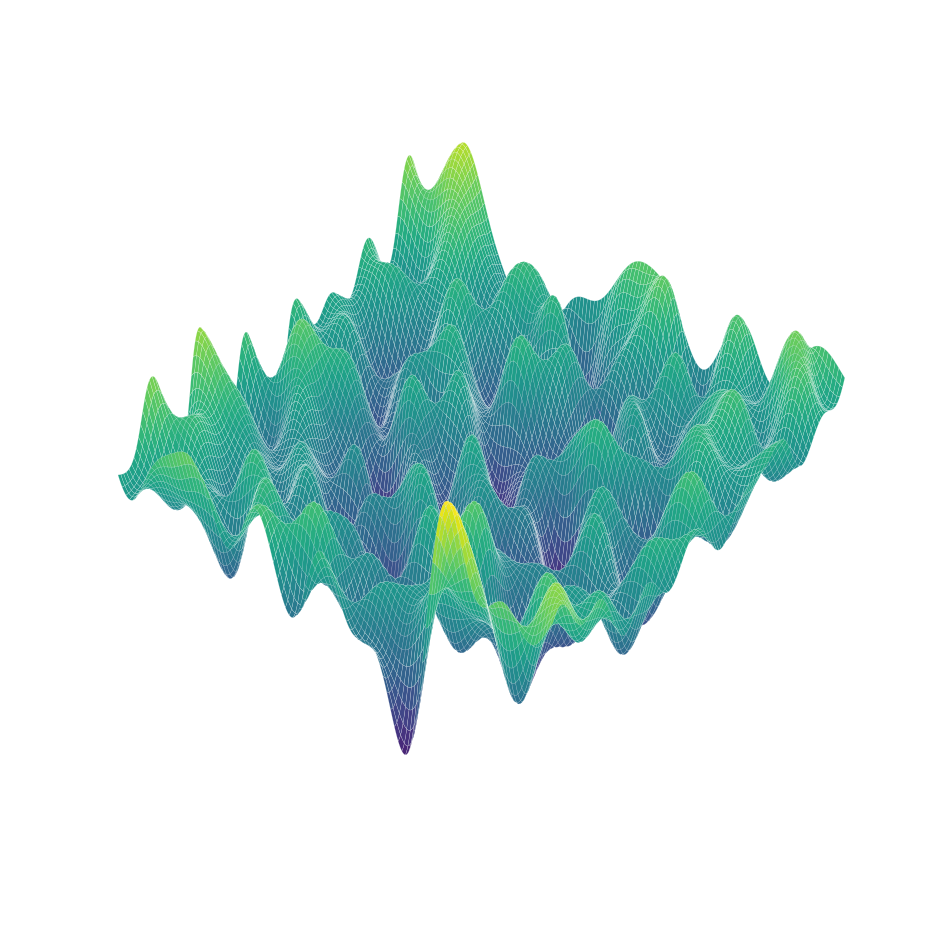

In [3]:
import numpy as np
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D

def generate_complex_landscape(x, y):
    z = 0.05 * (x**2 + y**2)
    np.random.seed(42)
    num_waves = 25
    for _ in range(num_waves):
        freq_x = np.random.uniform(0.5, 4.0)
        freq_y = np.random.uniform(0.5, 4.0)
        amp = np.random.uniform(0.1, 0.6)
        phase_x = np.random.uniform(0, 2 * np.pi)
        phase_y = np.random.uniform(0, 2 * np.pi)
        z += amp * np.sin(freq_x * x + phase_x) * np.cos(freq_y * y + phase_y)
    return z

def plot_complex_landscape(
    range_xy=(-6, 6),
    resolution=600,
    cmap='viridis',
    output_file='./complex_loss_white.pdf'
):
    x = np.linspace(range_xy[0], range_xy[1], resolution)
    y = np.linspace(range_xy[0], range_xy[1], resolution)
    X, Y = np.meshgrid(x, y)
    Z = generate_complex_landscape(X, Y)

    fig = plt.figure(figsize=(12, 12), facecolor='white')
    ax = fig.add_subplot(111, projection='3d')
    ax.set_facecolor('white') 

    surf = ax.plot_surface(
        X, Y, Z,
        cmap=cmap,
        edgecolor=(1.0, 1.0, 1.0, 0.45), 
        linewidth=0.25,                  
        rcount=120,                      
        ccount=120,               
        antialiased=True,
        shade=True                       
    )

    point_x, point_y = 2.0, 1.5
    point_z = generate_complex_landscape(point_x, point_y)
    
    ax.scatter(
        [point_x], [point_y], [point_z + 0.5],
        color='#FF00FF',                 
        s=150,                           
        edgecolor='white',               
        linewidth=0.5,
        depthshade=False,                
        zorder=10
    )

    ax.set_axis_off()
    ax.xaxis.set_pane_color((1.0, 1.0, 1.0, 0.0))
    ax.yaxis.set_pane_color((1.0, 1.0, 1.0, 0.0))
    ax.zaxis.set_pane_color((1.0, 1.0, 1.0, 0.0))

    ax.view_init(elev=40, azim=-55)
    
    plt.savefig(
        output_file,
        format='pdf',
        bbox_inches='tight',
        pad_inches=0,
        facecolor='white',               
        edgecolor='none',
        dpi=600
    )
    print(f"图像已保存至: {output_file}")
    
    plt.show()
    plt.close(fig)

plot_complex_landscape(
    resolution=600,
    cmap='viridis',
    output_file='./nonconvex_landscape.pdf'
)

图像已保存至: ./saddle_landscape.pdf


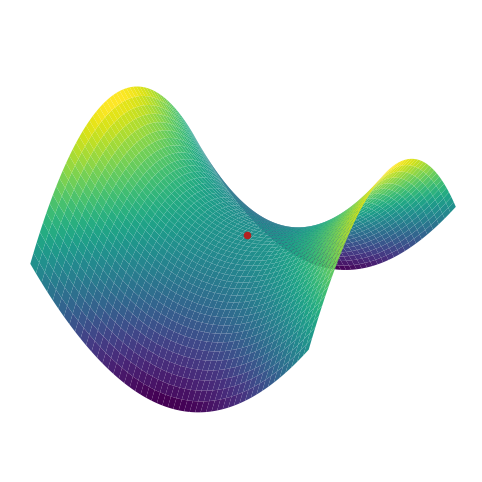

In [4]:
import numpy as np
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D

def plot_saddle_surface(
    range_xy=(-2, 2),
    resolution=600,
    cmap='viridis',
    output_file='saddle_landscape.pdf',
    save=True,
    show=True
):
    x = np.linspace(range_xy[0], range_xy[1], resolution)
    y = np.linspace(range_xy[0], range_xy[1], resolution)
    x, y = np.meshgrid(x, y)
    z = x**2 - y**2

    fig = plt.figure(figsize=(10, 6), facecolor='white')
    ax = fig.add_subplot(111, projection='3d')

    # ===== 改动1：关闭自动深度排序，使 zorder 生效 =====
    ax.computed_zorder = False

    # 绘制曲面（zorder=1，画在底层）
    surf = ax.plot_surface(
        x, y, z,
        cmap=cmap,
        edgecolor='none',
        antialiased=True,
        shade=True,
        zorder=1,
    )

    # ===== 改动2：红点 zorder=10 置顶 + depthshade=False 不褪色 + 加大 =====
    ax.scatter(0, 0, 0, color='#B22222', s=20, depthshade=False, zorder=10)

    # 隐藏所有坐标轴元素
    ax.set_axis_off()
    ax.xaxis.pane.set_visible(False)
    ax.yaxis.pane.set_visible(False)
    ax.zaxis.pane.set_visible(False)

    try:
        ax.set_box_aspect(None, zoom=1.2)
    except TypeError:
        ax.set_box_aspect(None)

    if save:
        plt.savefig(
            output_file,
            format='pdf',
            bbox_inches='tight',
            pad_inches=0,
            transparent=True
        )
        print(f"图像已保存至: {output_file}")

    if show:
        plt.show()
    plt.close(fig)

plot_saddle_surface(
    resolution=600,
    cmap='viridis',
    output_file='./saddle_landscape.pdf'
)

图像已保存至: ./ill_conditioned.pdf


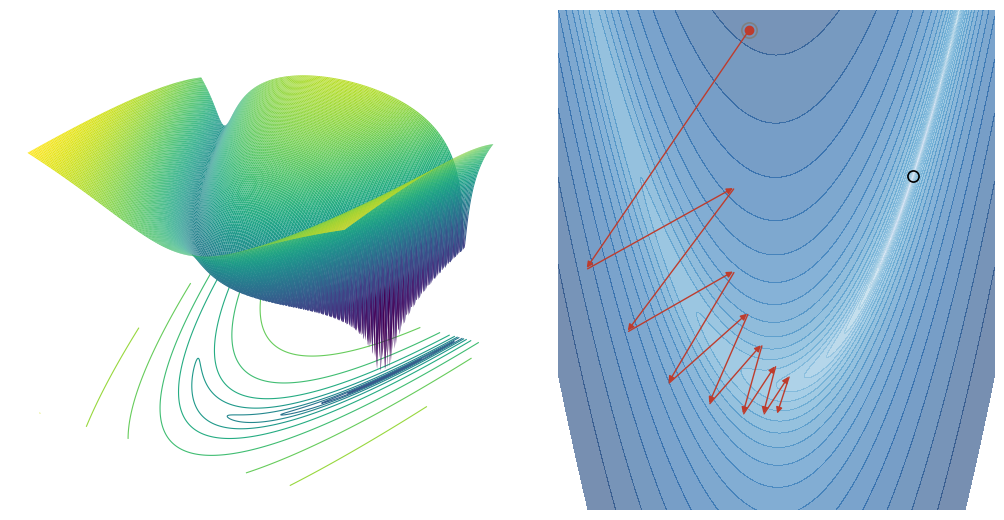

In [5]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.gridspec import GridSpec

def rosenbrock(x, y):
    return (1 - x)**2 + 100*(y - x**2)**2

def plot_rosenbrock_pair(
    range_x=(-1.6, 1.6),
    range_y=(-0.6, 1.8),
    resolution=600,
    cmap3d='viridis',
    cmap2d='Blues',
    alpha2d=0.55,
    left_ratio=1.25,          # 左面板宽度比例，>1 左边更大
    zoom3d=1.2,               # 3D 再放大
    output_file='./ill_conditioned.pdf',
    save=True,
    show=True,
):
    # ---- 网格 ----
    x = np.linspace(*range_x, resolution)
    y = np.linspace(*range_y, resolution)
    X, Y = np.meshgrid(x, y)
    Zl = np.log10(np.clip(rosenbrock(X, Y), 1e-3, None))

    fig = plt.figure(figsize=(13, 6.5), facecolor='white')
    gs = GridSpec(1, 2, width_ratios=[left_ratio, 1], wspace=0.05)

    # ================= 左：3D 山沟 =================
    ax1 = fig.add_subplot(gs[0], projection='3d')
    ax1.set_facecolor('white')
    ax1.plot_surface(X, Y, Zl, cmap=cmap3d, rcount=150, ccount=150,
                     edgecolor='none', antialiased=True, shade=True)
    ax1.contour(X, Y, Zl, zdir='z', offset=-3.2, cmap=cmap3d,
                levels=12, linewidths=0.8)
    ax1.set_zlim(-3.2, 3)
    ax1.view_init(elev=28, azim=-62)
    ax1.set_axis_off()
    ax1.xaxis.pane.set_visible(False)
    ax1.yaxis.pane.set_visible(False)
    ax1.zaxis.pane.set_visible(False)
    try:
        ax1.set_box_aspect(None, zoom=zoom3d)   # 同参考代码的放大套路
    except TypeError:
        ax1.set_box_aspect(None)

    # ================= 右：等高线 + 轨迹 =================
    ax2 = fig.add_subplot(gs[1])
    ax2.set_facecolor('white')
    ax2.contourf(X, Y, Zl, levels=np.linspace(-3, 2.8, 30),
                 cmap=cmap2d, alpha=alpha2d)

    # 之字形轨迹
    T = [(-0.2,1.7), (-1.4,0.55), (-0.3,0.95), (-1.1,0.25), (-0.3,0.55),
         (-0.8,0.0), (-0.2,0.35), (-0.5,-0.1), (-0.1,0.20), (-0.25,-0.15),
         (0.0,0.1), (-0.1,-0.15), (0.1,0.05), (0.0,-0.15)]
    for (x0, y0), (x1, y1) in zip(T[:-1], T[1:]):
        ax2.annotate('', xy=(x1, y1), xytext=(x0, y0),
                     arrowprops=dict(arrowstyle='-|>', color='#BE3C2D',
                                     lw=1.0, mutation_scale=9))
    # 起点红点+灰圈；最小值空心黑圈
    ax2.plot(*T[0], 'o', color='#BE3C2D', markersize=6)
    ax2.plot(*T[0], 'o', mfc='none', mec='gray', mew=1.2, markersize=11)
    ax2.plot(1, 1, 'o', mfc='none', mec='black', mew=1.2, markersize=8)
    ax2.set_axis_off()

    # ---- 保存 / 显示（同参考代码套路）----
    if save:
        plt.savefig(output_file, format='pdf', bbox_inches='tight',
                    pad_inches=0, transparent=True)
        print(f"图像已保存至: {output_file}")
    if show:
        plt.show()
    plt.close(fig)

plot_rosenbrock_pair(
    resolution=600,
    cmap3d='viridis',
    output_file='./ill_conditioned.pdf',
)

图像已保存至: ./ill_conditioned_sovled.pdf


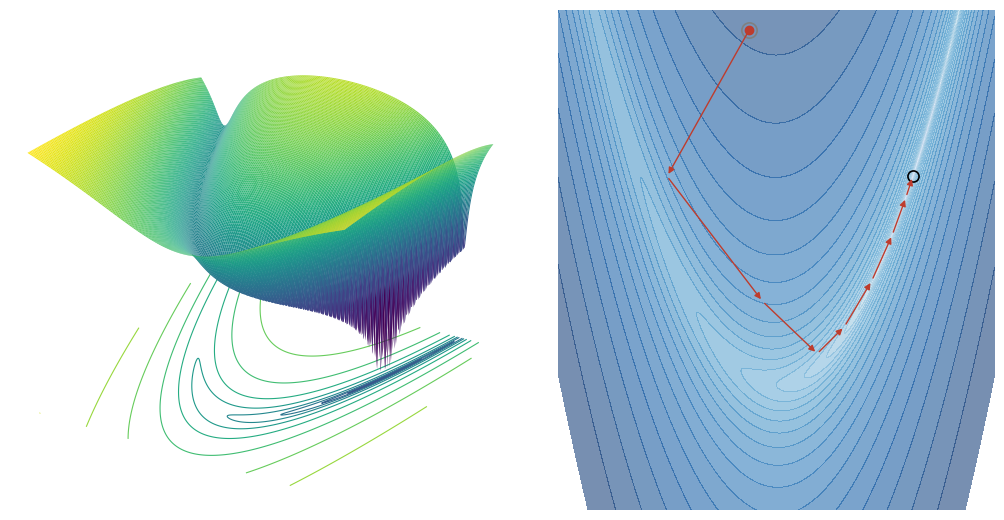

In [6]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.gridspec import GridSpec

def rosenbrock(x, y):
    return (1 - x)**2 + 100*(y - x**2)**2

def plot_rosenbrock_pair(
    range_x=(-1.6, 1.6),
    range_y=(-0.6, 1.8),
    resolution=600,
    cmap3d='viridis',
    cmap2d='Blues',
    alpha2d=0.55,
    left_ratio=1.25,          # 左面板宽度比例，>1 左边更大
    zoom3d=1.2,               # 3D 再放大
    output_file='./ill_conditioned.pdf',
    save=True,
    show=True,
):
    # ---- 网格 ----
    x = np.linspace(*range_x, resolution)
    y = np.linspace(*range_y, resolution)
    X, Y = np.meshgrid(x, y)
    Zl = np.log10(np.clip(rosenbrock(X, Y), 1e-3, None))

    fig = plt.figure(figsize=(13, 6.5), facecolor='white')
    gs = GridSpec(1, 2, width_ratios=[left_ratio, 1], wspace=0.05)

    # ================= 左：3D 山沟 =================
    ax1 = fig.add_subplot(gs[0], projection='3d')
    ax1.set_facecolor('white')
    ax1.plot_surface(X, Y, Zl, cmap=cmap3d, rcount=150, ccount=150,
                     edgecolor='none', antialiased=True, shade=True)
    ax1.contour(X, Y, Zl, zdir='z', offset=-3.2, cmap=cmap3d,
                levels=12, linewidths=0.8)
    ax1.set_zlim(-3.2, 3)
    ax1.view_init(elev=28, azim=-62)
    ax1.set_axis_off()
    ax1.xaxis.pane.set_visible(False)
    ax1.yaxis.pane.set_visible(False)
    ax1.zaxis.pane.set_visible(False)
    try:
        ax1.set_box_aspect(None, zoom=zoom3d)   # 同参考代码的放大套路
    except TypeError:
        ax1.set_box_aspect(None)

    # ================= 右：等高线 + 轨迹 =================
    ax2 = fig.add_subplot(gs[1])
    ax2.set_facecolor('white')
    ax2.contourf(X, Y, Zl, levels=np.linspace(-3, 2.8, 30),
                 cmap=cmap2d, alpha=alpha2d)

    # 动量法轨迹：初期轻微惯性震荡，迅速贴合谷底，沿谷平滑加速冲向 (1,1)
    T = [
        (-0.2, 1.7),   # 起点
        (-0.8, 1.0),   # 第一次横摆（惯性）
        (-0.1, 0.4),   # 动量拉回，迅速接近谷底线
        (0.3, 0.15),   # 稍微冲过中心线
        (0.5, 0.28),   # 完美贴合谷底线 (0.5^2 ≈ 0.25)
        (0.7, 0.5),    # 沿谷底加速 (0.7^2 ≈ 0.5)
        (0.85, 0.72),  # 继续加速
        (0.95, 0.90),  # 逼近最小值
        (1.0, 1.0)     # 精准到达空心圈
    ]
    for (x0, y0), (x1, y1) in zip(T[:-1], T[1:]):
        ax2.annotate('', xy=(x1, y1), xytext=(x0, y0),
                     arrowprops=dict(arrowstyle='-|>', color='#BE3C2D',
                                     lw=1.0, mutation_scale=9))
    # 起点红点+灰圈；最小值空心黑圈
    ax2.plot(*T[0], 'o', color='#BE3C2D', markersize=6)
    ax2.plot(*T[0], 'o', mfc='none', mec='gray', mew=1.2, markersize=11)
    ax2.plot(1, 1, 'o', mfc='none', mec='black', mew=1.2, markersize=8)
    ax2.set_axis_off()

    # ---- 保存 / 显示（同参考代码套路）----
    if save:
        plt.savefig(output_file, format='pdf', bbox_inches='tight',
                    pad_inches=0, transparent=True)
        print(f"图像已保存至: {output_file}")
    if show:
        plt.show()
    plt.close(fig)

plot_rosenbrock_pair(
    resolution=600,
    cmap3d='viridis',
    output_file='./ill_conditioned_sovled.pdf',
)

图像已保存至: ./ill_conditioned_curvature.pdf


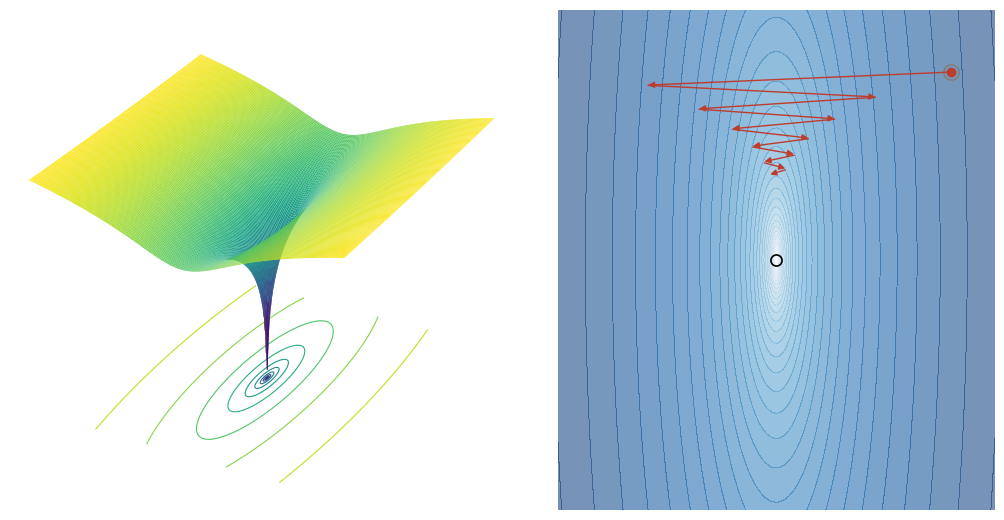

In [7]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.gridspec import GridSpec

def ill_conditioned_quadratic(x, y):
    return 100*x**2 + y**2

def plot_ill_conditioned_pair(
    range_x=(-1.5, 1.5),
    range_y=(-4, 4),
    resolution=600,
    cmap3d='viridis',
    cmap2d='Blues',
    alpha2d=0.55,
    left_ratio=1.25,
    zoom3d=1.2,
    output_file='./ill_conditioned.pdf',
    save=True,
    show=True,
):
    # ---- 网格 ----
    x = np.linspace(*range_x, resolution)
    y = np.linspace(*range_y, resolution)
    X, Y = np.meshgrid(x, y)
    Zl = np.log10(np.clip(ill_conditioned_quadratic(X, Y), 1e-3, None))

    fig = plt.figure(figsize=(13, 6.5), facecolor='white')
    gs = GridSpec(1, 2, width_ratios=[left_ratio, 1], wspace=0.05)

    # ================= 左：3D 狭谷 =================
    ax1 = fig.add_subplot(gs[0], projection='3d')
    ax1.set_facecolor('white')
    ax1.plot_surface(X, Y, Zl, cmap=cmap3d, rcount=150, ccount=150,
                     edgecolor='none', antialiased=True, shade=True)
    ax1.contour(X, Y, Zl, zdir='z', offset=-3.2, cmap=cmap3d,
                levels=12, linewidths=0.8)
    ax1.set_zlim(-3.2, 3)
    ax1.view_init(elev=28, azim=-62)
    ax1.set_axis_off()
    ax1.xaxis.pane.set_visible(False)
    ax1.yaxis.pane.set_visible(False)
    ax1.zaxis.pane.set_visible(False)
    try:
        ax1.set_box_aspect(None, zoom=zoom3d)
    except TypeError:
        ax1.set_box_aspect(None)

    # ================= 右：等高线 + 轨迹 =================
    ax2 = fig.add_subplot(gs[1])
    ax2.set_facecolor('white')
    ax2.contourf(X, Y, Zl, levels=np.linspace(-2, 2.5, 35),
                 cmap=cmap2d, alpha=alpha2d)

    # 病态轨迹：x（快方向）震荡衰减，y（慢方向）每步只爬 ~7%
    # 12 步后 y 还剩 1.35，离谷底一半多 —— "不好整到谷底"
    T = [(1.2,3.0),  (-0.9,2.79), (0.7,2.6),  (-0.55,2.41), (0.42,2.25),
         (-0.32,2.09), (0.24,1.94), (-0.18,1.81), (0.14,1.68), (-0.10,1.56),
         (0.08,1.45), (-0.06,1.35)]
    for (x0, y0), (x1, y1) in zip(T[:-1], T[1:]):
        ax2.annotate('', xy=(x1, y1), xytext=(x0, y0),
                     arrowprops=dict(arrowstyle='-|>', color='#BE3C2D',
                                     lw=1.0, mutation_scale=9))
    # 起点红点+灰圈；最小值空心黑圈
    ax2.plot(*T[0], 'o', color='#BE3C2D', markersize=6)
    ax2.plot(*T[0], 'o', mfc='none', mec='gray', mew=1.2, markersize=11)
    ax2.plot(0, 0, 'o', mfc='none', mec='black', mew=1.2, markersize=8)
    ax2.set_axis_off()

    # ---- 保存 / 显示 ----
    if save:
        plt.savefig(output_file, format='pdf', bbox_inches='tight',
                    pad_inches=0, transparent=True)
        print(f"图像已保存至: {output_file}")
    if show:
        plt.show()
    plt.close(fig)

plot_ill_conditioned_pair(
    resolution=600,
    cmap3d='viridis',
    output_file='./ill_conditioned_curvature.pdf',
)